# Physics 4B: Constitutive Law P12 with prior

*Note (xkan 1.0 port).* The final formula fits the data better than the one this tutorial originally showed (an RMSE of about 3e-4 against 7e-3) and contains the law's terms $0.42 F_{12}$ and $0.42 F_{13} F_{23}$. The product $F_{11} F_{21}$ comes out as several polynomial terms, which makes the formula longer than the original's five terms. The original output came from a development version of pykan; a search over eight seeds and three initialisations (pykan's of August 2024 among them) found no shorter formula.

In [1]:
from constitutive_laws_generator import LinearElasticConstitutiveLaw, NeoHookeanConstitutiveLaw
import copy
import torch
import matplotlib.pyplot as plt
import numpy as np
import random
from sympy import symbols, expand
from xkan import KANNetwork, fit, create_dataset_from_data
from xkan.symbolic import compile_formula
from xkan.viz import plot

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.use_deterministic_algorithms(True)
torch.set_default_dtype(torch.float64)

N = 1000
sigma = 0.2 # previously sigma = 0.2

F = torch.eye(3,3)[None,:,:].expand(N,3,3) + (torch.rand(N,3,3)*2-1)*sigma
det = torch.det(F)
F *= (det > 0)[:,None,None]

linear = LinearElasticConstitutiveLaw(young_modulus=1.0, poisson_ratio=0.2)
P_l = linear(F)
P11_l = P_l[:,[0],[0]]
P12_l = P_l[:,[0],[1]]

neo = NeoHookeanConstitutiveLaw(young_modulus=1.0, poisson_ratio=0.2)
P_n = neo(F)
P11_n = P_n[:,[0],[0]]
P12_n = P_n[:,[0],[1]]

# P11
# linear: P11 = 2 * mu * (F11 - 1) + lambda * (F11 + F22 + F33 - 3)
# neohookean: P11 = mu * (F11^2 + F12^2 + F13^2 - 1) + lambda * log(|F|)

# P12
# linear: P12 = mu * (F12 + F21)
# neohookean: P12 = mu * (F11 * F21 + F12 * F22 + F13 * F23)

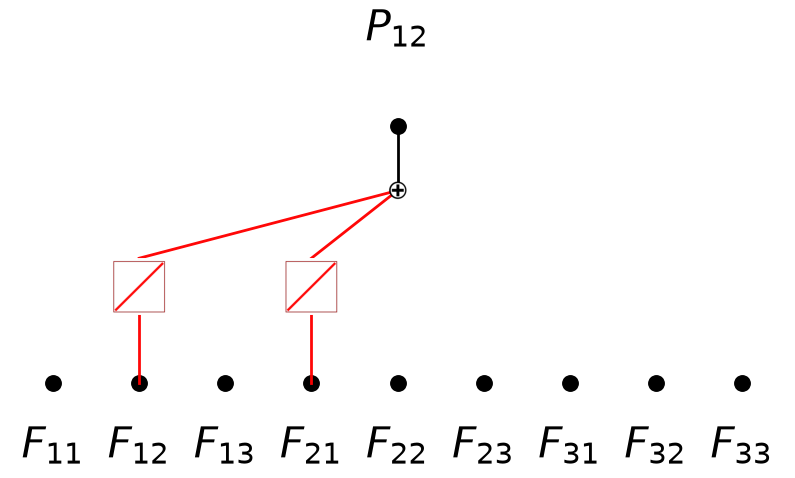

In [2]:
mu, lambda_ = linear.get_lame_parameters()
input_vars = F11, F12, F13, F21, F22, F23, F31, F32, F33 = symbols('F11 F12 F13 F21 F22 F23 F31 F32 F33')

# compile more terms in ground truth
# or make the network bigger
P12_l_expr = mu * (F12 + F21)

# seed=4: of eight seeds the one whose final formula fits best (see the note at the top)
model = compile_formula(input_vars, P12_l_expr, base_fun='identity', seed=4)

F_flatten = F.reshape(N, -1)

plot(model, F_flatten, in_vars=input_vars, out_vars=[r'$P_{12}$'], varscale=0.75, scale=1.0);

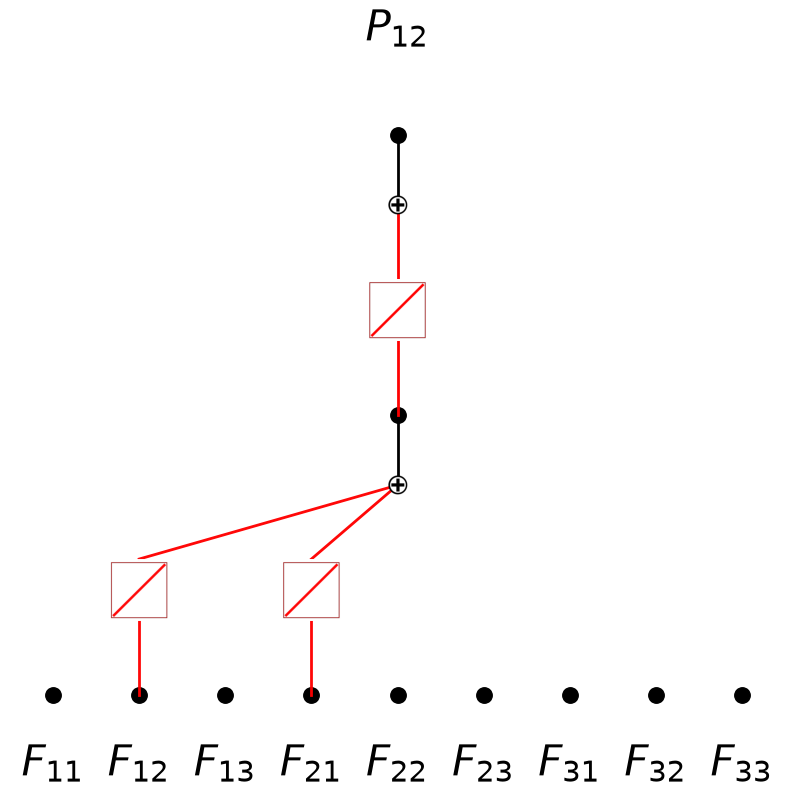

In [3]:
from xkan.interp import expand_depth, expand_width
model = expand_depth(model)
plot(model, F_flatten, in_vars=input_vars, out_vars=[r'$P_{12}$'], varscale=0.75, scale=1.0);

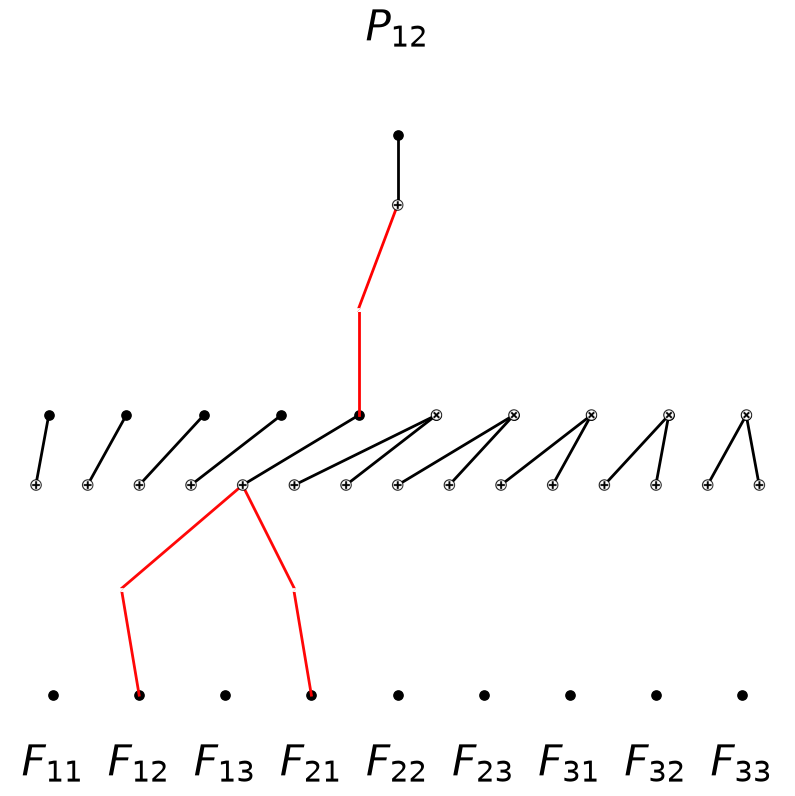

In [4]:
model = expand_width(model, 1, 5, sum_bool=False, mult_arity=2)
model = expand_width(model, 1, 4)
plot(model, F_flatten, in_vars=input_vars, out_vars=[r'$P_{12}$'], varscale=0.75, scale=1.0);

In [5]:
from xkan.interp import perturb
perturb(model, mode='all')

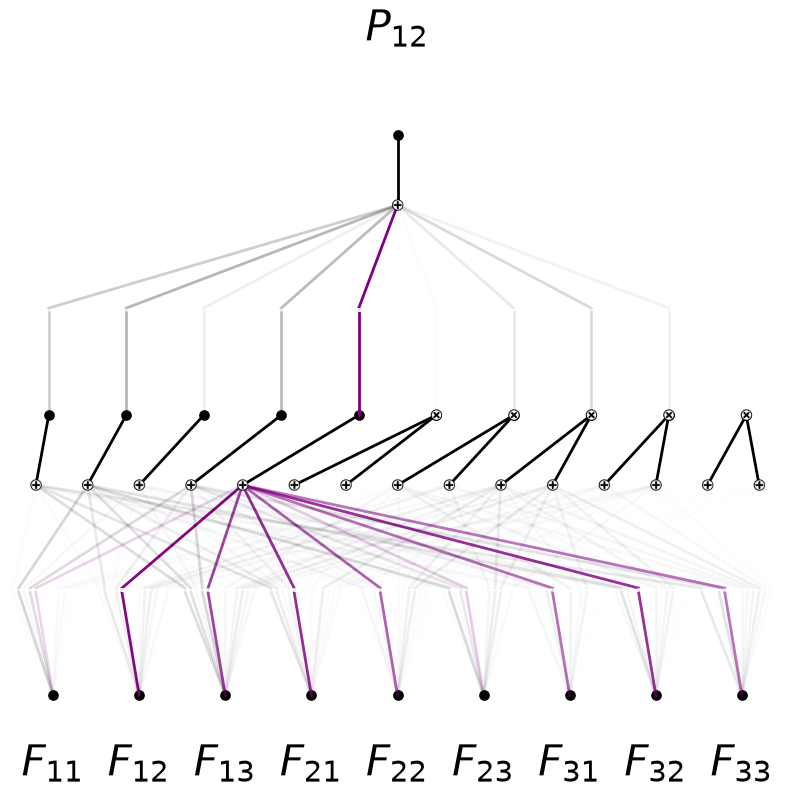

In [6]:
plot(model, F_flatten, in_vars=input_vars, out_vars=[r'$P_{12}$'], varscale=0.75, scale=1.0);

In [7]:
train, test = create_dataset_from_data(F_flatten, P12_n)
torch.sqrt(torch.mean((model(train['x']) - train['y'])**2))

tensor(0.9936, grad_fn=<SqrtBackward0>)

In [8]:
from xkan.utils import create_dataset_from_data

#train, test = create_dataset_from_data(F_flatten, P12_n)
history = fit(model, train, test, steps=100, lamb=1e-5)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.0012768714041565426 test RMSE 0.0018203543121943237


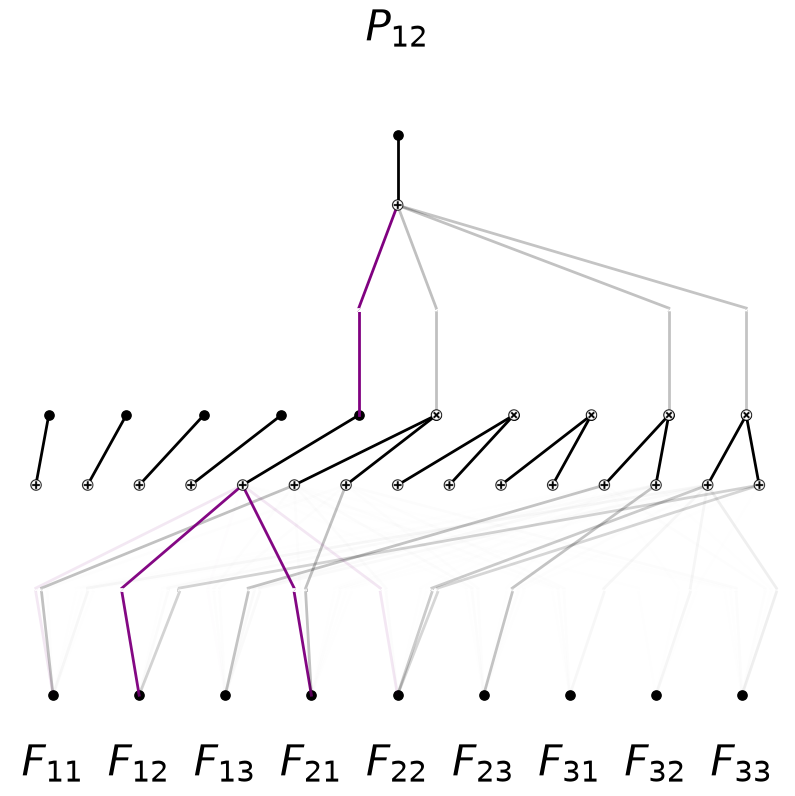

In [9]:
plot(model, train['x'], in_vars=input_vars, out_vars=[r'$P_{12}$'], varscale=0.75, scale=1.0);

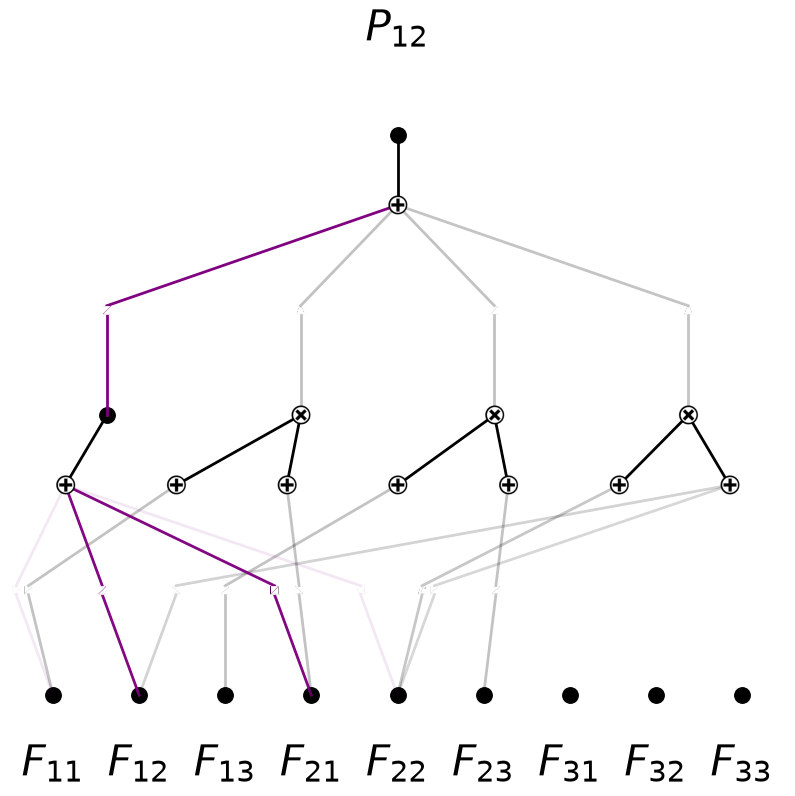

In [10]:
from xkan.interp import prune
model = prune(model, train['x'])
pruned = copy.deepcopy(model)  # a copy to come back to (xkan 1.0 networks keep no history)
plot(model, train['x'], in_vars=input_vars, out_vars=[r'$P_{12}$'], varscale=0.75, scale=1.0);

In [11]:
model = copy.deepcopy(pruned)

In [12]:
history = fit(model, train, test, steps=100)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 1.9408251381983834e-05 test RMSE 2.4677395861639375e-05


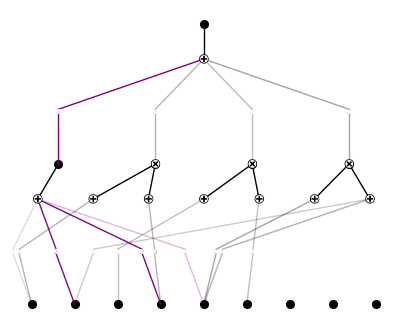

In [13]:
plot(model, train['x']);

In [14]:
from xkan.symbolic import auto_symbolic
model = prune(model, train['x'])
auto_symbolic(model, train['x'])

fixing (0,0,2) with 0
fixing (0,0,3) with 0
fixing (0,0,4) with 0
fixing (0,0,5) with 0
fixing (0,0,6) with 0
fixing (0,1,1) with 0


fixing (0,1,2) with 0
fixing (0,1,3) with 0
fixing (0,1,4) with 0
fixing (0,1,5) with 0
skipping (0,2,0) since already symbolic
fixing (0,2,1) with 0
fixing (0,2,2) with 0


fixing (0,2,4) with 0
fixing (0,2,5) with 0
fixing (0,2,6) with 0
fixing (0,3,1) with 0
fixing (0,3,3) with 0
fixing (0,3,4) with 0


fixing (0,3,5) with 0
fixing (0,3,6) with 0
fixing (0,4,1) with 0
fixing (0,4,2) with 0


fixing (0,4,3) with 0
fixing (0,4,4) with 0
skipping (0,5,0) since already symbolic
fixing (0,5,1) with 0
fixing (0,5,2) with 0
fixing (0,5,3) with 0
fixing (0,5,5) with 0


fixing (0,5,6) with 0
skipping (0,6,0) since already symbolic
fixing (0,6,1) with 0
fixing (0,6,2) with 0
fixing (0,6,3) with 0
fixing (0,6,4) with 0


... (15 outputs left out)

fixing (1,1,0) with x^2, r2=0.9976008888916991, c=2


fixing (1,2,0) with x, r2=0.9999972876223185, c=1


fixing (1,3,0) with sin, r2=0.9992816516827295, c=2


{(0, 0, 0): ('x^2', np.float64(0.9996847916257456), np.int64(2)),
 (0, 0, 1): ('x', np.float64(0.9999571091768962), np.int64(1)),
 (0, 1, 0): ('x^2', np.float64(0.999998226174029), np.int64(2)),
 (0, 1, 6): ('x^2', np.float64(0.9999906468590188), np.int64(2)),
 (0, 2, 3): ('x', np.float64(0.9999988717825772), np.int64(1)),
 (0, 3, 0): ('x^2', np.float64(0.9999998250436694), np.int64(2)),
 (0, 3, 2): ('x', np.float64(0.9999786091758646), np.int64(1)),
 (0, 4, 0): ('x^2', np.float64(0.9949994286327708), np.int64(2)),
 (0, 4, 5): ('x', np.float64(0.9344139127309385), np.int64(1)),
 (0, 4, 6): ('x', np.float64(0.9877359567298913), np.int64(1)),
 (0, 5, 4): ('x', np.float64(0.9999971533498228), np.int64(1)),
 (1, 0, 0): ('x', np.float64(0.9999999946492666), np.int64(1)),
 (1, 1, 0): ('x^2', np.float64(0.9976008888916991), np.int64(2)),
 (1, 2, 0): ('x', np.float64(0.9999972876223185), np.int64(1)),
 (1, 3, 0): ('sin', np.float64(0.9992816516827295), np.int64(2))}

In [15]:
# auto_symbolic may pick functions with a singularity (1/sqrt(x), log, ...): the guard keeps the refit finite
history = fit(model, train, test, steps=100, forward_kwargs=dict(singularity_avoiding=True))
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.00034234519318751777 test RMSE 0.0003699934453568416


In [16]:
from xkan.symbolic import symbolic_formula
from xkan.utils import ex_round
# expanded before rounding: rounding first can drop a term (a small factor in front of a large inner one)
ex_round(expand(symbolic_formula(model, var=input_vars)[0][0]), 2)

-0.02*F11**2*F21**2 + 0.15*F11**2*F21 - 0.07*F11*F21**2 + 0.11*F11*F21 + 0.12*F12**2 + 0.44*F12 + 0.42*F13*F23 + 0.09*F21**2 + 0.15*F21 + 0.35*F22**2 - 0.73*F22 - 0.07*sin(0.01*F12**2*F22 - 0.63*F12**2 + 0.03*F12*F22 - 1.96*F12 - 0.06*F22**2 + 3.35*F22 + 7.56) + 0.31